# Task 66: Robustness Testing Technical Report

Benchmark model robustness across data split instability, FGSM adversarial attacks, Gaussian jitter, boundary projections, and out-of-distribution stress; synthesize empirical failure modes and mitigation architectures.


=== CLEAN BASELINE PERFORMANCE (Test N=61) ===
Accuracy: 0.8197, Precision: 0.7895, Recall: 0.9091, F1: 0.8451

=== COMPREHENSIVE ROBUSTNESS BENCHMARK TABLE ===
         Protocol  Epsilon  accuracy  precision   recall       f1  Mean_Confidence  Flip_Rate
   Clean Baseline     0.00  0.819672   0.789474 0.909091 0.845070         0.761161   0.000000
   Gaussian Noise     0.05  0.836066   0.794872 0.939394 0.861111         0.762104   0.016393
   Gaussian Noise     0.10  0.819672   0.789474 0.909091 0.845070         0.760849   0.000000
   Gaussian Noise     0.20  0.819672   0.789474 0.909091 0.845070         0.761300   0.032787
   Gaussian Noise     0.35  0.836066   0.794872 0.939394 0.861111         0.753920   0.114754
   Gaussian Noise     0.50  0.868852   0.878788 0.878788 0.878788         0.768150   0.114754
 FGSM Adversarial     0.05  0.770492   0.756757 0.848485 0.800000         0.749537   0.049180
 FGSM Adversarial     0.10  0.754098   0.736842 0.848485 0.788732         0.736796   0.

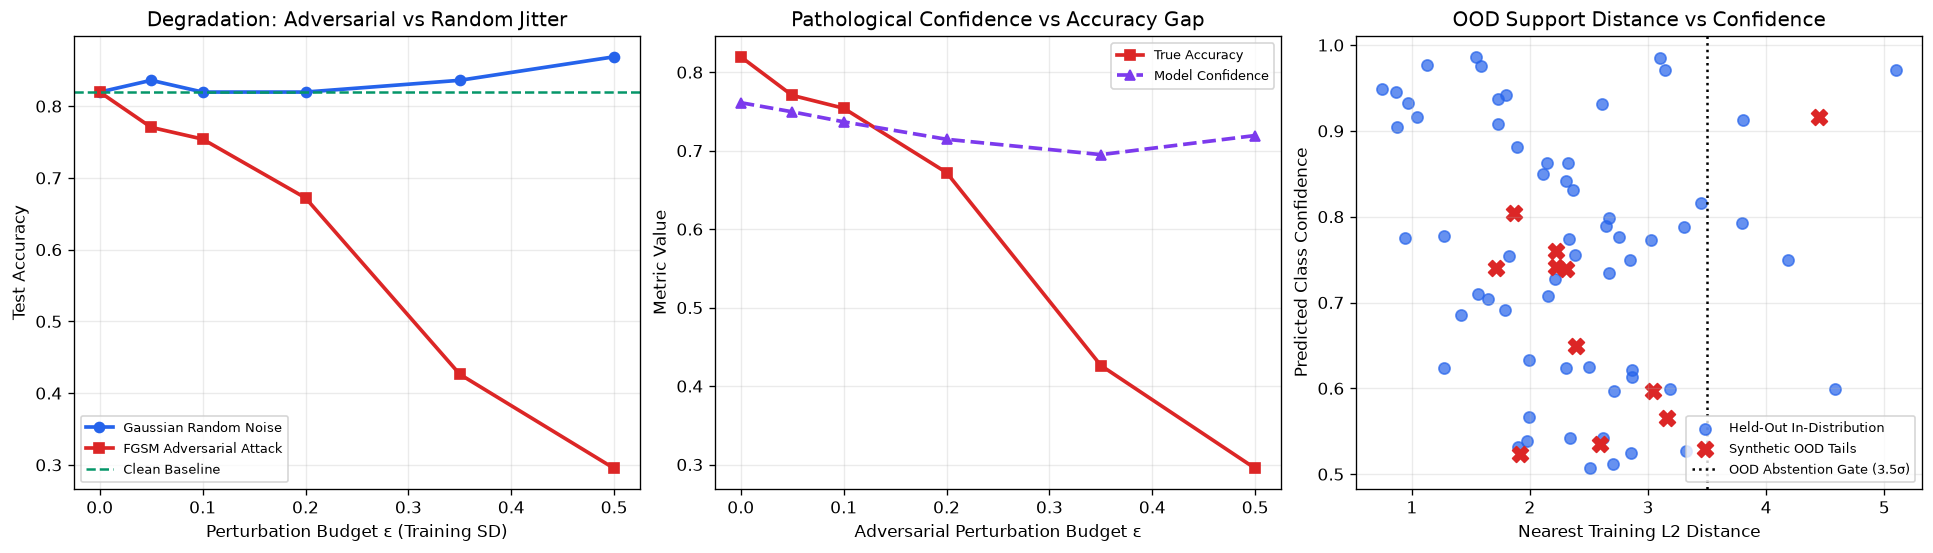

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_66_Robustness_Testing_Technical_Report/heart.csv"), Path("Heart_Disease_Tasks/Task_66_Robustness_Testing_Technical_Report/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Stratified split
def stratified_split(X, y, test_size=0.2, seed=66):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=66)

# Standardization
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

def calc_metrics(y_true, y_pred):
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    acc = (tp + tn) / max(len(y_true), 1)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# Baseline clean evaluation
clean_prob = model.predict_proba(X_test_s)
clean_preds = (clean_prob >= 0.5).astype(int)
clean_scores = calc_metrics(y_test, clean_preds)
print(f"=== CLEAN BASELINE PERFORMANCE (Test N={len(y_test)}) ===")
print(f"Accuracy: {clean_scores['accuracy']:.4f}, Precision: {clean_scores['precision']:.4f}, Recall: {clean_scores['recall']:.4f}, F1: {clean_scores['f1']:.4f}")

# Perturbation generators
lower = np.quantile(X_train_s, 0.01, axis=0)
upper = np.quantile(X_train_s, 0.99, axis=0)

epsilons = [0.05, 0.10, 0.20, 0.35, 0.50]
results = []
results.append({
    "Protocol": "Clean Baseline",
    "Epsilon": 0.0,
    **clean_scores,
    "Mean_Confidence": float(np.mean(np.maximum(clean_prob, 1 - clean_prob))),
    "Flip_Rate": 0.0
})

# 1. Random Gaussian Jitter
rng = np.random.default_rng(660)
for eps in epsilons:
    jitter = rng.normal(0, eps, size=X_test_s.shape)
    x_jit = np.clip(X_test_s + jitter, lower, upper)
    p_jit = model.predict_proba(x_jit)
    preds = (p_jit >= 0.5).astype(int)
    results.append({
        "Protocol": "Gaussian Noise",
        "Epsilon": eps,
        **calc_metrics(y_test, preds),
        "Mean_Confidence": float(np.mean(np.maximum(p_jit, 1 - p_jit))),
        "Flip_Rate": float(np.mean(preds != clean_preds))
    })

# 2. FGSM Gradient Adversarial
for eps in epsilons:
    prob = np.clip(clean_prob, 1e-8, 1 - 1e-8)
    grad = ((prob - y_test) * prob * (1 - prob))[:, None] * model.w[None, :]
    x_adv = np.clip(X_test_s + eps * np.sign(grad), lower, upper)
    p_adv = model.predict_proba(x_adv)
    preds = (p_adv >= 0.5).astype(int)
    results.append({
        "Protocol": "FGSM Adversarial",
        "Epsilon": eps,
        **calc_metrics(y_test, preds),
        "Mean_Confidence": float(np.mean(np.maximum(p_adv, 1 - p_adv))),
        "Flip_Rate": float(np.mean(preds != clean_preds))
    })

# 3. Decision Boundary Projection
scores = X_test_s @ model.w + model.b
norm_sq = max(float(model.w @ model.w), 1e-12)
margin = np.maximum(np.abs(scores) + 1e-4, 1e-4)
x_boundary = np.clip(X_test_s - (np.sign(scores) * margin / norm_sq)[:, None] * model.w[None, :], lower, upper)
p_bound = model.predict_proba(x_boundary)
b_preds = (p_bound >= 0.5).astype(int)
results.append({
    "Protocol": "Boundary-Directed",
    "Epsilon": 0.0,
    **calc_metrics(y_test, b_preds),
    "Mean_Confidence": float(np.mean(np.maximum(p_bound, 1 - p_bound))),
    "Flip_Rate": float(np.mean(b_preds != clean_preds))
})

df_bench = pd.DataFrame(results)
print("\n=== COMPREHENSIVE ROBUSTNESS BENCHMARK TABLE ===")
print(df_bench.to_string(index=False))

# 4. Out-of-Distribution (OOD) Stress Analysis
continuous_idx = [features.index(f) for f in ["age", "trestbps", "chol", "thalach", "oldpeak"] if f in features]
train_df = pd.DataFrame(X_train, columns=features)
q01 = train_df.quantile(0.01)
q99 = train_df.quantile(0.99)
med = train_df.median()

ood_cases = []
for f in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    if f in features:
        r_low = med.copy(); r_low[f] = q01[f]
        r_high = med.copy(); r_high[f] = q99[f]
        ood_cases.append({"Scenario": f"{f} low-tail", **r_low.to_dict()})
        ood_cases.append({"Scenario": f"{f} high-tail", **r_high.to_dict()})

composite = med.copy()
for f in ["age", "trestbps", "chol", "oldpeak"]:
    if f in features: composite[f] = q99[f]
if "thalach" in features: composite["thalach"] = q01["thalach"]
ood_cases.append({"Scenario": "Combined Extreme Tails", **composite.to_dict()})

df_ood = pd.DataFrame(ood_cases)
X_ood = df_ood[features].to_numpy(float)
X_ood_s = (X_ood - mu) / sd
p_ood = model.predict_proba(X_ood_s)
conf_ood = np.maximum(p_ood, 1 - p_ood)
dist_ood = [float(np.sqrt(np.min(np.sum((X_train_s - pt)**2, axis=1)))) for pt in X_ood_s]
df_ood["Pred_Probability"] = p_ood
df_ood["Confidence"] = conf_ood
df_ood["Nearest_Train_L2_Dist"] = dist_ood

print("\n=== OUT-OF-DISTRIBUTION STRESS TEST DIAGNOSTICS ===")
print(df_ood[["Scenario", "Pred_Probability", "Confidence", "Nearest_Train_L2_Dist"]].to_string(index=False))

# Diagnostic Visualizations
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

# Plot 1: Accuracy Degradation Curves
eps_axis = [0.0] + epsilons
acc_gauss = [clean_scores["accuracy"]] + [r["accuracy"] for r in results if r["Protocol"] == "Gaussian Noise"]
acc_adv = [clean_scores["accuracy"]] + [r["accuracy"] for r in results if r["Protocol"] == "FGSM Adversarial"]

axes[0].plot(eps_axis, acc_gauss, marker="o", color="#2563eb", linewidth=2.2, label="Gaussian Random Noise")
axes[0].plot(eps_axis, acc_adv, marker="s", color="#dc2626", linewidth=2.2, label="FGSM Adversarial Attack")
axes[0].axhline(clean_scores["accuracy"], color="#059669", linestyle="--", label="Clean Baseline")
axes[0].set_xlabel("Perturbation Budget ε (Training SD)")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Degradation: Adversarial vs Random Jitter")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

# Plot 2: Confidence vs Accuracy Disparity
conf_adv = [float(np.mean(np.maximum(clean_prob, 1 - clean_prob)))] + [r["Mean_Confidence"] for r in results if r["Protocol"] == "FGSM Adversarial"]
axes[1].plot(eps_axis, acc_adv, marker="s", color="#dc2626", linewidth=2.2, label="True Accuracy")
axes[1].plot(eps_axis, conf_adv, marker="^", color="#7c3aed", linewidth=2.2, linestyle="--", label="Model Confidence")
axes[1].set_xlabel("Adversarial Perturbation Budget ε")
axes[1].set_ylabel("Metric Value")
axes[1].set_title("Pathological Confidence vs Accuracy Gap")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

# Plot 3: OOD Nearest Distance vs Model Confidence
in_dist_dists = [float(np.sqrt(np.min(np.sum((X_train_s - pt)**2, axis=1)))) for pt in X_test_s]
in_dist_conf = np.maximum(clean_prob, 1 - clean_prob)
axes[2].scatter(in_dist_dists, in_dist_conf, color="#2563eb", alpha=0.7, s=45, label="Held-Out In-Distribution")
axes[2].scatter(dist_ood, conf_ood, color="#dc2626", s=90, marker="X", label="Synthetic OOD Tails")
axes[2].axvline(3.5, color="black", linestyle=":", linewidth=1.5, label="OOD Abstention Gate (3.5σ)")
axes[2].set_xlabel("Nearest Training L2 Distance")
axes[2].set_ylabel("Predicted Class Confidence")
axes[2].set_title("OOD Support Distance vs Confidence")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.25)

plt.show()
